<a href="https://colab.research.google.com/github/Lorenzito/ProgramacionParaAnaliticaDescriptivayPredicitva/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Varela Ollervides Lorenzo
*   Matrícula: 273524

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [1]:
# Tu código aquí

# 1. Importación de las bibliotecas que se usan a lo largo de la práctica:
#    - numpy y pandas para manejar los datos.
#    - matplotlib y seaborn para las gráficas.
#    - scipy.stats para el Q-Q plot de los residuos.
#    - statsmodels para el VIF (multicolinealidad) y para obtener los valores p del modelo.
#    - scikit-learn para entrenar la regresión lineal y calcular sus métricas.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 2. Carga del archivo advertising.csv (se encuentra en la misma carpeta que este notebook).
df = pd.read_csv('advertising.csv')

# 3. Primeras filas del dataframe, para revisar la estructura y el nombre de las columnas.
print("Primeras filas del dataset:")
print(df.head())

# 4. Descripción estadística de cada variable (conteo, media, desviación estándar,
#    mínimo, cuartiles y máximo) para conocer la escala de cada una.
print("\nDescripción estadística del dataset:")
print(df.describe())


Primeras filas del dataset:
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Descripción estadística del dataset:
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

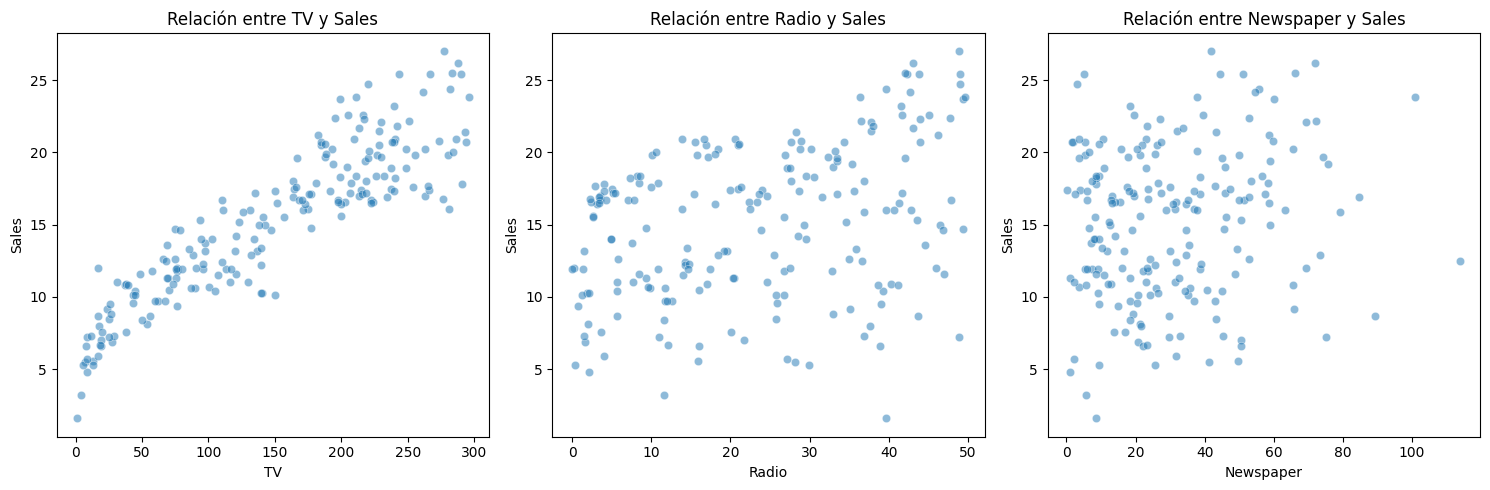

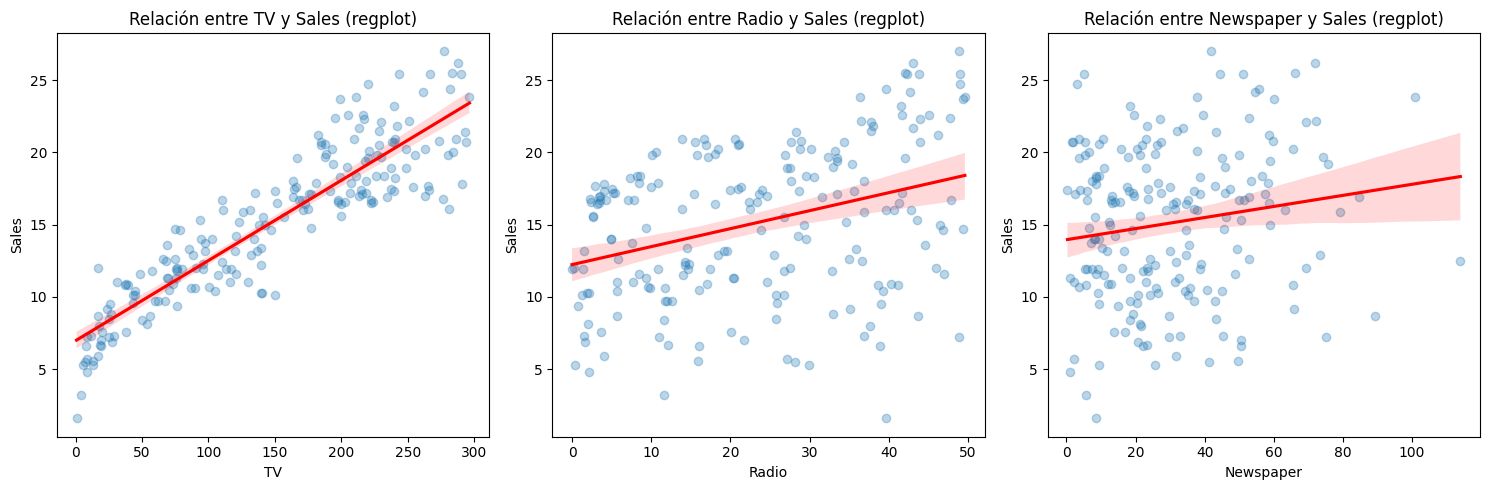

In [2]:
# Gráficos de dispersión

# Se separan los predictores (X: TV, Radio y Newspaper) de la variable dependiente (y: Sales),
# porque las gráficas y los modelos siguientes trabajan con esta separación.
X = df.drop(columns='Sales')
y = df['Sales']

# 1. Diagramas de dispersión: uno por cada variable independiente contra Sales,
#    para observar si la nube de puntos sigue una tendencia lineal.
plt.figure(figsize=(15, 5))
for i, col in enumerate(X.columns):
    plt.subplot(1, 3, i + 1)
    sns.scatterplot(x=X[col], y=y, alpha=0.5)
    plt.title(f"Relación entre {col} y Sales")
    plt.xlabel(col)
    plt.ylabel("Sales")

plt.tight_layout()
plt.show()

# 2. regplot: los mismos puntos con la recta de regresión ajustada (en rojo) y su banda
#    de confianza, que ayuda a ver la dirección y qué tan marcada es la tendencia lineal.
plt.figure(figsize=(15, 5))
for i, col in enumerate(X.columns):
    plt.subplot(1, 3, i + 1)
    sns.regplot(x=X[col], y=y, scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'})
    plt.title(f"Relación entre {col} y Sales (regplot)")

plt.tight_layout()
plt.show()


**Respuesta:**

Interpretación visual de la relación de cada medio con `Sales`:

- **TV:** es la relación lineal más clara. Los puntos forman una tendencia ascendente bien definida y se mantienen cerca de la recta roja del regplot, cuya banda de confianza es muy angosta. Se nota que la nube se abre un poco conforme aumenta la inversión en TV (con poca inversión las ventas van de 2 a 12 aproximadamente y con mucha inversión de 16 a 27), pero la tendencia lineal positiva domina.
- **Radio:** también hay una tendencia positiva (la recta sube de 12 a poco más de 18 en ventas), pero los puntos están mucho más dispersos alrededor de la recta: para un mismo nivel de inversión en radio las ventas varían mucho. Es una relación lineal positiva, pero más débil que la de TV.
- **Newspaper:** los puntos no siguen un patrón definido; para cualquier nivel de inversión las ventas se reparten entre 2 y 27. La recta del regplot tiene poca pendiente y su banda de confianza se ensancha mucho en los valores altos de Newspaper, donde hay pocos datos. Visualmente no se aprecia una relación lineal clara entre la inversión en periódicos y las ventas.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

Matriz de correlación:
                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.901208
Radio      0.054809  1.000000   0.354104  0.349631
Newspaper  0.056648  0.354104   1.000000  0.157960
Sales      0.901208  0.349631   0.157960  1.000000


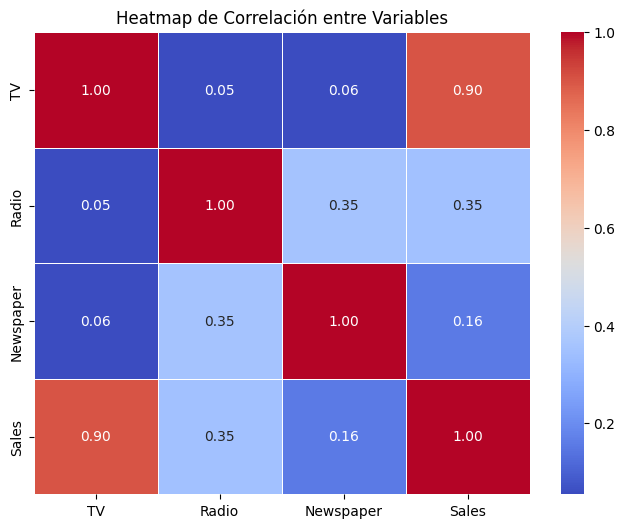

In [3]:
# Correlación y heatmap

# 1. Matriz de correlación de Pearson entre todas las variables del dataframe:
#    mide la fuerza y la dirección de la relación lineal entre cada par de variables.
correlation_matrix = df.corr()
print("Matriz de correlación:")
print(correlation_matrix)

# 2. Heatmap de la matriz: los colores y los valores anotados permiten ubicar rápidamente
#    qué variables se relacionan más con Sales y si hay correlación alta entre predictores.
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', cbar=True, linewidths=0.5)
plt.title("Heatmap de Correlación entre Variables")
plt.show()


**Respuesta:**

- **Variables más correlacionadas con `Sales`:** TV es por mucho la más correlacionada, con **0.90** (0.901208), una correlación positiva fuerte. Le sigue Radio con **0.35** (0.349631), una correlación positiva moderada-baja, y al final Newspaper con apenas **0.16** (0.157960), una correlación débil. Esto coincide con lo observado en las gráficas de dispersión de la sección 2.1.
- **Correlación entre predictores:** no hay correlación alta entre ellos. La mayor es la de Radio con Newspaper, **0.35** (0.354104), que es moderada-baja; TV prácticamente no se relaciona con Radio (**0.05**) ni con Newspaper (**0.06**). Por lo tanto, la matriz de correlación no muestra señales de que dos predictores aporten la misma información.

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

### Análisis de Multicolinealidad ###
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


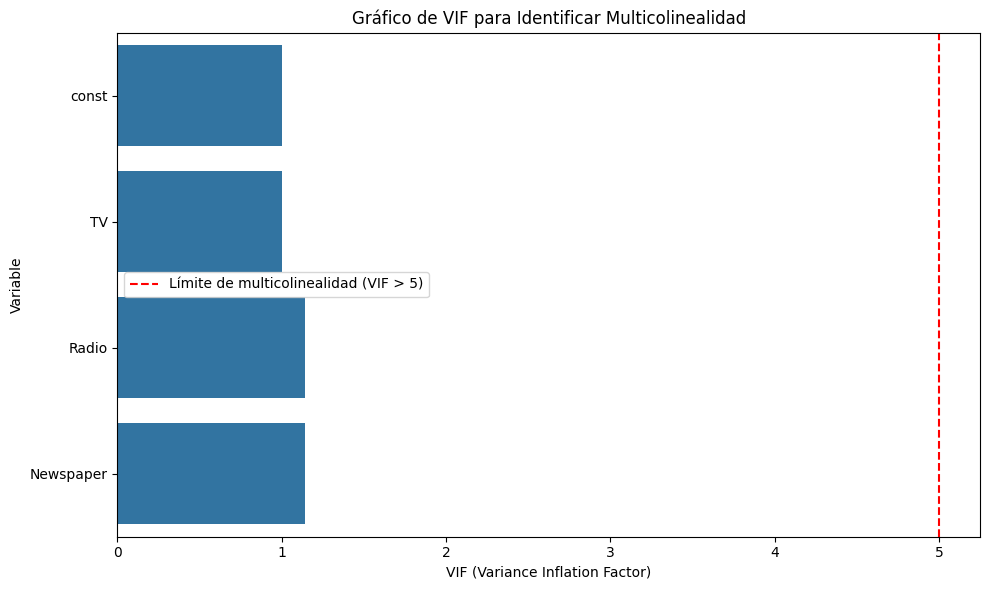

In [4]:
#Multicolinealidad

# 1. Cálculo del VIF (Variance Inflation Factor) de cada predictor.
#    Se agrega una constante a la matriz de predictores (como en el ejemplo de clase) para que
#    cada regresión auxiliar de un predictor sobre los demás incluya intercepto.
X_vif = add_constant(X)
vif_data = pd.DataFrame()
vif_data['Variable'] = X_vif.columns
vif_data['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

print("### Análisis de Multicolinealidad ###")
print(vif_data)

# 2. Diagrama de barras del VIF con una línea de referencia en 5,
#    que es el límite a partir del cual se considera multicolinealidad alta.
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data)
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()


**Respuesta:**

- **¿Algún VIF mayor a 5 o a 10?** No. Los VIF de los predictores son **TV = 1.004611**, **Radio = 1.144952** y **Newspaper = 1.145187**; todos están muy cerca de 1 y muy lejos de la línea de referencia en 5 del diagrama de barras (y por lo tanto también de 10). La fila `const` (VIF = 1.000000) corresponde a la constante que se agregó para el cálculo, no a un predictor, así que no se toma en cuenta para el diagnóstico.
- **Implicaciones para el modelo:** un VIF cercano a 1 significa que la varianza del coeficiente de cada medio casi no se infla por su relación con los otros dos medios. No hay multicolinealidad, de modo que los coeficientes que estime el modelo deberían ser estables y se pueden interpretar por separado (el efecto de cada medio manteniendo los otros constantes). No es necesario eliminar variables por este motivo. Esto es consistente con la sección 2.2, donde la correlación más alta entre predictores fue de solo 0.35 (Radio y Newspaper).

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [5]:
#ntrenamiento del Modelo (Todas las Variables Independientes)

# 1. Se crea y entrena el modelo de regresión lineal múltiple con TV, Radio y Newspaper (X)
#    como variables independientes y Sales (y) como variable dependiente.
#    No se escalan las variables para que los coeficientes queden en las unidades originales
#    y puedan leerse directamente en términos de ventas.
model = LinearRegression()
model.fit(X, y)

# 2. Intercepto y coeficientes estimados por el modelo.
coefficients = model.coef_
intercept = model.intercept_

print(f"Intercepto: {intercept:.4f}")
print("Coeficientes:")
for i, coef in enumerate(coefficients):
    print(f"  {X.columns[i]}: {coef:.4f}")

# Ecuación del modelo con los coeficientes obtenidos
equation = f"Sales = {intercept:.4f} "
for i, coef in enumerate(coefficients):
    equation += f"+ ({coef:.4f} * {X.columns[i]}) "
print("\nEcuación del modelo:")
print(equation)


Intercepto: 4.6251
Coeficientes:
  TV: 0.0544
  Radio: 0.1070
  Newspaper: 0.0003

Ecuación del modelo:
Sales = 4.6251 + (0.0544 * TV) + (0.1070 * Radio) + (0.0003 * Newspaper) 


**Respuesta:**

El modelo estimado es **Sales = 4.6251 + 0.0544·TV + 0.1070·Radio + 0.0003·Newspaper**.

- **Intercepto (4.6251):** son las ventas que el modelo estima cuando no se invierte nada en ninguno de los tres medios. Es el nivel base de ventas; en este caso sí es un punto con sentido, porque en la descripción de la Parte 1 se ve que hay inversiones mínimas cercanas a cero (Radio llega a 0.0 y TV a 0.7).
- **TV (0.0544):** por cada unidad adicional invertida en publicidad televisiva, las ventas aumentan en promedio **0.0544 unidades**, manteniendo constantes Radio y Newspaper.
- **Radio (0.1070):** por cada unidad adicional invertida en radio, las ventas aumentan en promedio **0.1070 unidades**, manteniendo constantes TV y Newspaper. Por unidad invertida es el coeficiente más alto, pero hay que recordar que la inversión en radio se mueve en un rango mucho menor que la de TV (de 0 a 49.6 contra 0.7 a 296.4, según la descripción de la Parte 1), por lo que los coeficientes no se pueden comparar directamente para decir qué medio pesa más.
- **Newspaper (0.0003):** por cada unidad adicional invertida en periódicos, las ventas cambian apenas **0.0003 unidades**, manteniendo constantes los otros dos medios. Es un efecto prácticamente nulo, lo que concuerda con la falta de relación lineal vista en la sección 2.1 y con su baja correlación (0.16) en la sección 2.2.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

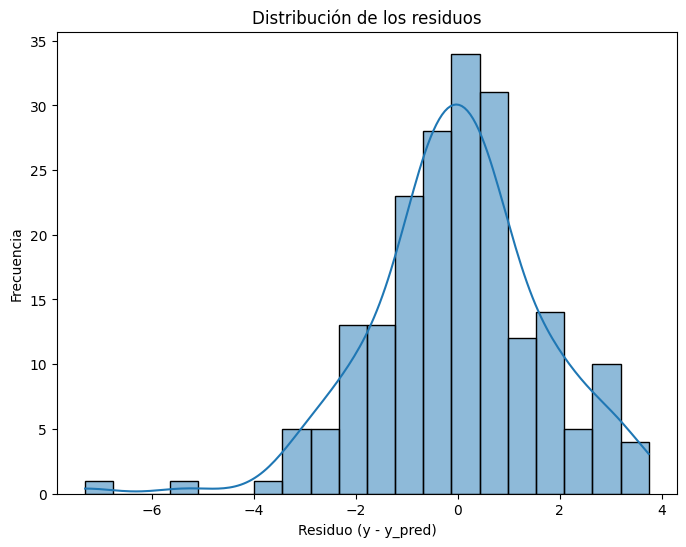

In [6]:
#Normalidad de los residuos

# 1. Predicciones del modelo y cálculo de los residuos (valor real menos valor predicho).
y_pred = model.predict(X)
residuos = y - y_pred

# 2. Histograma de los residuos con su curva de densidad (KDE),
#    para comparar visualmente su forma con la de una distribución normal.
plt.figure(figsize=(8, 6))
sns.histplot(residuos, bins=20, kde=True)
plt.xlabel("Residuo (y - y_pred)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los residuos")
plt.show()


**Respuesta:**

Los residuos parecen distribuirse **aproximadamente** de forma normal, aunque no de manera perfecta. El histograma tiene forma de campana, está centrado cerca de 0 y la mayoría de los residuos queda entre -4 y 4, con la barra más alta (alrededor de 34 observaciones) justo en el centro. Sin embargo, la distribución no es simétrica: hacia la izquierda aparece una cola larga con dos residuos aislados, cerca de -7 y de -5.5, que no tienen equivalente del lado derecho (donde los residuos no pasan de aproximadamente 3.7). Esto indica una ligera asimetría negativa: en unos pocos casos el modelo predijo ventas bastante más altas que las reales.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

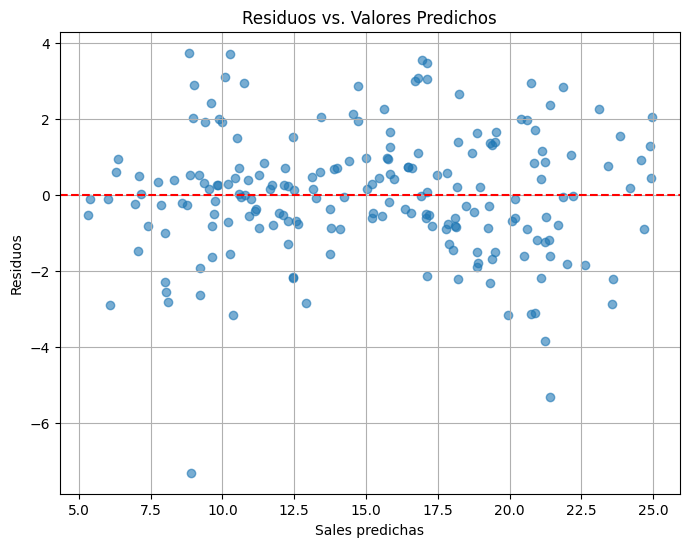

In [7]:
# Homocedasticidad

# 1. Residuos contra valores predichos, con una línea horizontal en 0.
#    Si la varianza de los errores es constante (homocedasticidad), los puntos deben
#    repartirse al azar alrededor de 0 con una amplitud parecida en todo el rango.
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuos, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Sales predichas")
plt.ylabel("Residuos")
plt.title("Residuos vs. Valores Predichos")
plt.grid(True)
plt.show()


**Respuesta:**

No se observa un patrón claro. Los residuos se reparten de forma aleatoria por arriba y por abajo de la línea en 0 a lo largo de todo el rango de ventas predichas (de 5 a 25 aproximadamente), y la mayoría se mantiene en una franja de amplitud parecida, entre -3 y 4. No aparece una forma de embudo (que la dispersión crezca o se reduzca conforme aumenta el valor predicho), por lo que el supuesto de homocedasticidad parece razonable. Lo único que sobresale son dos residuos negativos grandes, uno cerca de -7.3 (con una predicción alrededor de 9) y otro cerca de -5.3 (con una predicción alrededor de 21.5), que son los mismos valores aislados de la cola izquierda que se vieron en el histograma de la sección 4.2.

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

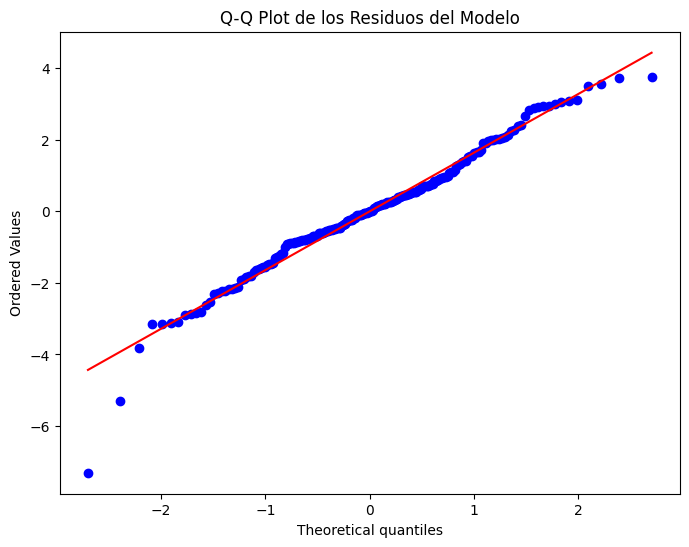

In [8]:
#Q-Q Plot

# 1. Q-Q plot de los residuos contra los cuantiles de una distribución normal.
#    Si los puntos siguen la línea diagonal, los residuos son aproximadamente normales.
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos del Modelo")
plt.show()


**Respuesta:**

- **a) Alineación con la diagonal:** en la parte central del gráfico (aproximadamente entre los cuantiles teóricos -2 y 2) los puntos quedan prácticamente sobre la línea roja, así que la mayor parte de los residuos se comporta como una distribución normal.
- **b) Desviaciones sistemáticas:** en los extremos sí hay desviaciones. En la cola izquierda los dos residuos más bajos (cerca de -5.3 y -7.3) quedan muy por debajo de la línea, lo que indica una cola izquierda más pesada que la de una normal, es decir, una asimetría negativa. En la cola derecha los últimos puntos quedan un poco por debajo de la línea (los residuos más altos no llegan a 4), lo que indica que esa cola es más corta de lo esperado.

En conclusión, la normalidad de los residuos se cumple de forma aproximada en el centro de la distribución, pero no en las colas, principalmente por los dos residuos negativos grandes que ya se habían visto en las secciones 4.2 y 4.3.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [9]:
#Evaluación del Modelo

# 1. Métricas de ajuste del modelo comparando las ventas reales (y) con las predichas (y_pred):
mse = mean_squared_error(y, y_pred)  # a) Error cuadrático medio
rmse = np.sqrt(mse)                  # b) Raíz del MSE, en las mismas unidades que Sales
r2 = r2_score(y, y_pred)             # c) Proporción de la variabilidad de Sales explicada por el modelo

print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")


Error Cuadrático Medio (MSE): 2.7060
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Coeficiente de Determinación (R²): 0.9026


**Respuesta:**

- **MSE = 2.7060:** es el promedio de los errores al cuadrado. Como está en unidades de ventas al cuadrado, es difícil de interpretar solo; sirve sobre todo para comparar modelos (mientras más bajo, mejor).
- **RMSE = 1.6450:** está en las mismas unidades que `Sales`, así que indica que las predicciones se alejan en promedio alrededor de **1.65 unidades** de las ventas reales. Comparado con las ventas promedio de **15.13** y su desviación estándar de **5.28** (Parte 1), es un error pequeño: aproximadamente una tercera parte de la variación natural de las ventas.
- **R² = 0.9026:** el modelo explica el **90.26 %** de la variabilidad de las ventas a partir de la inversión en TV, Radio y Newspaper; solo un 9.74 % queda sin explicar.

En conjunto, las métricas indican un **buen ajuste** del modelo. Hay que tomar en cuenta que se calcularon con los mismos 200 registros con los que se entrenó el modelo, por lo que describen qué tan bien se ajusta a estos datos.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

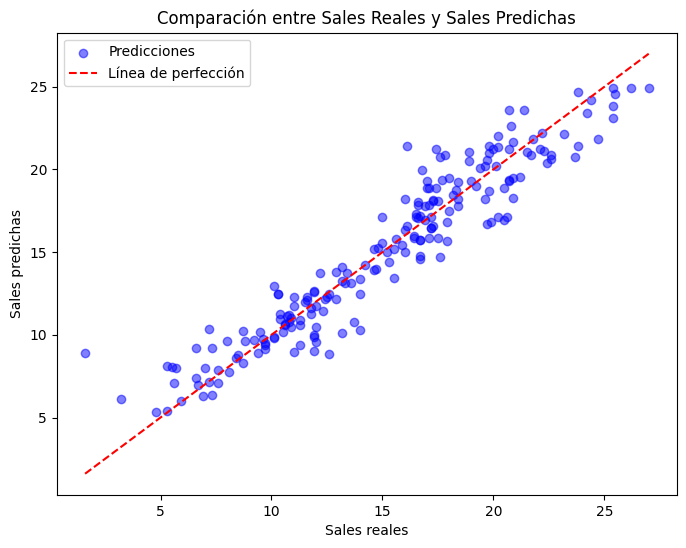

In [10]:
#Visualización de las Predicciones

# 1. Ventas reales contra ventas predichas. La línea punteada roja representa la predicción
#    perfecta (predicho = real): mientras más cerca estén los puntos de ella, mejor el ajuste.
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')
plt.title("Comparación entre Sales Reales y Sales Predichas")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.legend()
plt.show()


**Respuesta:**

Los puntos se concentran alrededor de la línea de predicción perfecta en todo el rango de ventas, lo que confirma visualmente el buen ajuste que indicó el R² de 0.9026 en la sección 4.5. La mejor coincidencia se da en las ventas intermedias (de 8 a 20 aproximadamente), donde los puntos están más pegados a la línea.

De la gráfica también se obtiene información sobre dónde falla el modelo:
- **En ventas bajas sobreestima:** los puntos con ventas reales menores a 7 quedan por encima de la línea; el caso más claro es una venta real de 1.6 que el modelo predijo cerca de 9.
- **En ventas altas tiende a subestimar:** las ventas reales más altas (de 25 a 27) se predicen entre 23 y 25 aproximadamente, por debajo de la línea.

Es decir, el modelo funciona muy bien en la zona central de los datos y pierde precisión en los extremos.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [11]:
#P-values

# 1. Se ajusta el mismo modelo con statsmodels (OLS) para obtener los valores p de cada coeficiente.
#    statsmodels no agrega el intercepto por sí solo, por eso se añade una constante a X.
X_const = sm.add_constant(X)
model_sm = sm.OLS(y, X_const).fit()

# 2. Resumen del modelo: coeficientes, errores estándar, estadístico t y P>|t| de cada variable.
print(model_sm.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        06:26:37   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**Respuesta:**

- **Variables con p-value menor a 0.05:** en la columna P>|t| la constante, **TV** y **Radio** tienen un valor de **0.000**, muy por debajo de 0.05. Sus estadísticos t son altos (39.592 para TV y 12.604 para Radio) y sus intervalos de confianza al 95 % no incluyen el 0 (TV de 0.052 a 0.057 y Radio de 0.090 a 0.124). **Newspaper** tiene un p-value de **0.954**, muy por encima de 0.05, con t = 0.058 y un intervalo de -0.011 a 0.012 que sí incluye el 0.
- **Conclusión:** la inversión en TV y en Radio tiene un efecto estadísticamente significativo sobre las ventas; podemos afirmar con confianza que sus coeficientes son distintos de cero. En cambio, una vez que el modelo ya incluye TV y Radio, la inversión en periódicos no aporta un efecto significativo sobre las ventas: su coeficiente no se distingue de cero. Esto coincide con lo observado en las secciones 2.1 (sin relación lineal clara), 2.2 (correlación de 0.16) y 4.1 (coeficiente de 0.0003). El resumen también confirma el ajuste de la sección 4.5, con un R-squared de 0.903 y un Adj. R-squared de 0.901.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Respuesta:**

En la Parte 3 **no se detectaron variables con multicolinealidad**: los VIF fueron TV = 1.004611, Radio = 1.144952 y Newspaper = 1.145187, todos muy por debajo de 5 (y de 10), y en la sección 2.2 la correlación más alta entre predictores fue de apenas 0.35. Como esta parte solo aplica en el caso de haber detectado multicolinealidad, **no hay ninguna variable que eliminar**. El modelo "sin multicolinealidad" usa los mismos tres predictores (TV, Radio y Newspaper) que el modelo de la Parte 4, por lo que sería idéntico a él: mismo intercepto y coeficientes (sección 4.1), mismos residuos (secciones 4.2 a 4.4), mismas métricas (sección 4.5) y mismos valores p (sección 4.7). Por esta razón no se repiten aquí las subsecciones; los resultados de la Parte 4 son los que corresponden a este modelo.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**Respuesta:**

Sí se detectó una variable sin relación lineal con `Sales`: **Newspaper**. En la sección 2.1 sus puntos no siguen un patrón definido y la recta del regplot es casi plana; en la sección 2.2 su correlación con Sales fue la más baja (0.16); en la sección 4.1 su coeficiente fue prácticamente nulo (0.0003), y en la sección 4.7 su p-value fue de 0.954, lejos de 0.05. Por lo tanto se elimina Newspaper y se construye un nuevo modelo solo con **TV** y **Radio**, repitiendo los pasos de la Parte 4.

### 6.1 Entrenamiento del Modelo (TV y Radio)

1. Entrena un modelo de regresión lineal múltiple usando TV y Radio como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno: ¿Qué significa cada uno de los coeficientes en términos de ventas?

In [12]:
# Entrenamiento del Modelo (sin Newspaper)

# 1. Nuevo conjunto de predictores sin Newspaper, que fue la variable que no mostró
#    una relación lineal clara con Sales.
X_p6 = df[['TV', 'Radio']]

# Se entrena el modelo de regresión lineal múltiple solo con TV y Radio.
model_p6 = LinearRegression()
model_p6.fit(X_p6, y)

# 2. Intercepto y coeficientes del nuevo modelo.
coefficients_p6 = model_p6.coef_
intercept_p6 = model_p6.intercept_

print(f"Intercepto: {intercept_p6:.4f}")
print("Coeficientes:")
for i, coef in enumerate(coefficients_p6):
    print(f"  {X_p6.columns[i]}: {coef:.4f}")

# Ecuación del modelo con los coeficientes obtenidos
equation_p6 = f"Sales = {intercept_p6:.4f} "
for i, coef in enumerate(coefficients_p6):
    equation_p6 += f"+ ({coef:.4f} * {X_p6.columns[i]}) "
print("\nEcuación del modelo:")
print(equation_p6)


Intercepto: 4.6309
Coeficientes:
  TV: 0.0544
  Radio: 0.1072

Ecuación del modelo:
Sales = 4.6309 + (0.0544 * TV) + (0.1072 * Radio) 


**Respuesta:**

El modelo estimado es **Sales = 4.6309 + 0.0544·TV + 0.1072·Radio**.

- **Intercepto (4.6309):** son las ventas que el modelo estima cuando no se invierte nada en TV ni en Radio.
- **TV (0.0544):** por cada unidad adicional invertida en TV, las ventas aumentan en promedio **0.0544 unidades**, manteniendo constante la inversión en Radio.
- **Radio (0.1072):** por cada unidad adicional invertida en radio, las ventas aumentan en promedio **0.1072 unidades**, manteniendo constante la inversión en TV.

Los valores son prácticamente iguales a los del modelo completo de la sección 4.1 (intercepto 4.6251, TV 0.0544 y Radio 0.1070): quitar Newspaper casi no movió los demás coeficientes, lo que confirma que esa variable no estaba aportando al modelo.

### 6.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.
2. Grafica un histograma con KDE de los residuos.
3. ¿Los residuos parecen distribuirse normalmente?

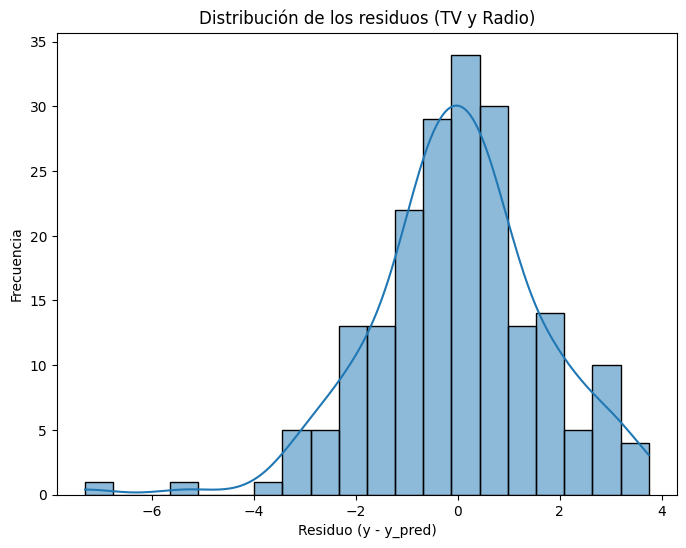

In [13]:
# Normalidad de los residuos (sin Newspaper)

# 1. Predicciones del nuevo modelo y sus residuos (valor real menos valor predicho).
y_pred_p6 = model_p6.predict(X_p6)
residuos_p6 = y - y_pred_p6

# 2. Histograma con KDE de los residuos para comparar su forma con una distribución normal.
plt.figure(figsize=(8, 6))
sns.histplot(residuos_p6, bins=20, kde=True)
plt.xlabel("Residuo (y - y_pred)")
plt.ylabel("Frecuencia")
plt.title("Distribución de los residuos (TV y Radio)")
plt.show()


**Respuesta:**

Los residuos de este modelo también se distribuyen **aproximadamente** de forma normal, y su histograma es prácticamente igual al de la sección 4.2: forma de campana centrada cerca de 0, la mayoría de los residuos entre -4 y 4 y la barra más alta (alrededor de 34 observaciones) en el centro. Se mantiene la misma cola izquierda con dos residuos aislados cerca de -7 y -5.5, sin equivalente del lado derecho, así que persiste la ligera asimetría negativa. Eliminar Newspaper no cambió la forma de la distribución de los errores.

### 6.3 Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

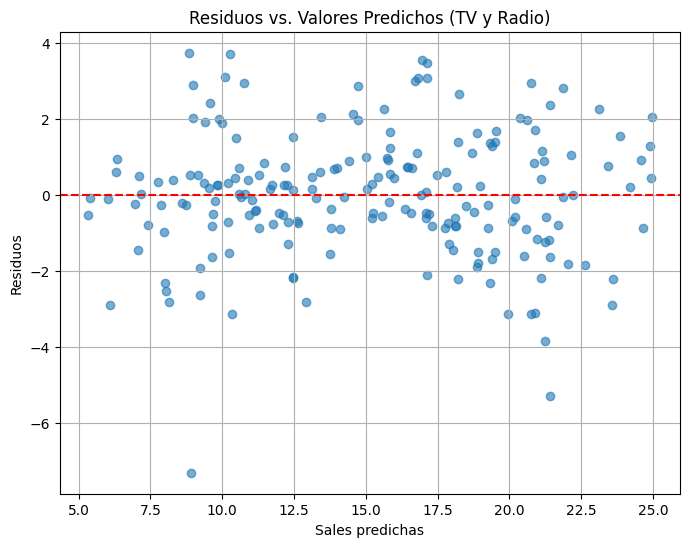

In [14]:
# Homocedasticidad (sin Newspaper)

# 1. Residuos contra valores predichos con una línea horizontal en 0, para revisar si la
#    dispersión de los errores es aleatoria y de amplitud parecida en todo el rango.
plt.figure(figsize=(8, 6))
plt.scatter(y_pred_p6, residuos_p6, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Sales predichas")
plt.ylabel("Residuos")
plt.title("Residuos vs. Valores Predichos (TV y Radio)")
plt.grid(True)
plt.show()


**Respuesta:**

No se observan patrones. Igual que en la sección 4.3, los residuos se dispersan de forma aleatoria alrededor de 0 en todo el rango de ventas predichas (de 5 a 25 aproximadamente), casi todos dentro de una franja de -3 a 4 de amplitud parecida y sin forma de embudo, por lo que el supuesto de homocedasticidad sigue siendo razonable. Los únicos puntos que sobresalen siguen siendo los dos residuos negativos grandes (cerca de -7.3 y -5.3).

### 6.4 Q-Q Plot

1. Graficar el Q-Q Plot.
2. Interpreta el gráfico.

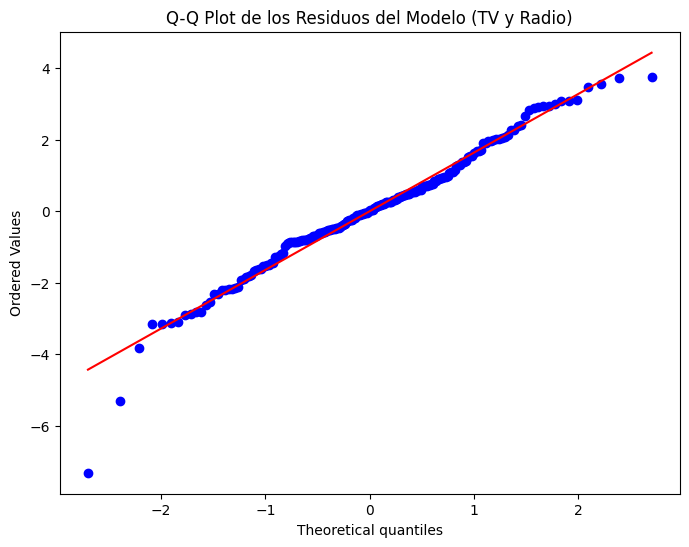

In [15]:
# Q-Q Plot (sin Newspaper)

# 1. Q-Q plot de los residuos del nuevo modelo contra los cuantiles de una normal.
plt.figure(figsize=(8, 6))
stats.probplot(residuos_p6, dist="norm", plot=plt)
plt.title("Q-Q Plot de los Residuos del Modelo (TV y Radio)")
plt.show()


**Respuesta:**

El Q-Q plot es prácticamente igual al de la sección 4.4. En la zona central (aproximadamente entre los cuantiles teóricos -2 y 2) los puntos siguen la línea diagonal, por lo que la mayoría de los residuos se comporta como una normal. En los extremos hay desviaciones sistemáticas: en la cola izquierda los dos residuos más bajos (cerca de -5.3 y -7.3) quedan muy por debajo de la línea, señal de una cola izquierda más pesada (asimetría negativa), y en la cola derecha los últimos puntos quedan un poco por debajo de la línea. La normalidad se cumple de manera aproximada, con las mismas excepciones en las colas que el modelo con tres variables.

### 6.5 Evaluación del Modelo

1. Calcula las métricas: a) MSE, b) RMSE, c) R².
2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?

In [16]:
# Evaluación del Modelo (sin Newspaper)

# 1. Métricas de ajuste del nuevo modelo con las ventas reales y las predichas.
mse_p6 = mean_squared_error(y, y_pred_p6)  # a) Error cuadrático medio
rmse_p6 = np.sqrt(mse_p6)                  # b) Raíz del MSE, en unidades de Sales
r2_p6 = r2_score(y, y_pred_p6)             # c) Coeficiente de determinación

print(f"Error Cuadrático Medio (MSE): {mse_p6:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse_p6:.4f}")
print(f"Coeficiente de Determinación (R²): {r2_p6:.4f}")


Error Cuadrático Medio (MSE): 2.7061
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Coeficiente de Determinación (R²): 0.9026


**Respuesta:**

- **MSE = 2.7061:** prácticamente igual al del modelo completo (2.7060 en la sección 4.5); la diferencia es de una diezmilésima.
- **RMSE = 1.6450:** idéntico al del modelo completo; las predicciones se alejan en promedio alrededor de **1.65 unidades** de las ventas reales, un error pequeño frente a las ventas promedio de 15.13 y su desviación estándar de 5.28 (Parte 1).
- **R² = 0.9026:** también igual al del modelo completo; el modelo explica el **90.26 %** de la variabilidad de las ventas usando solo TV y Radio.

Las métricas indican el mismo **buen ajuste** que el modelo de la Parte 4, pero con una variable menos. Es decir, quitar Newspaper no empeoró el ajuste. Igual que en la sección 4.5, las métricas se calcularon con los mismos datos de entrenamiento.

### 6.6 Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.
2. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

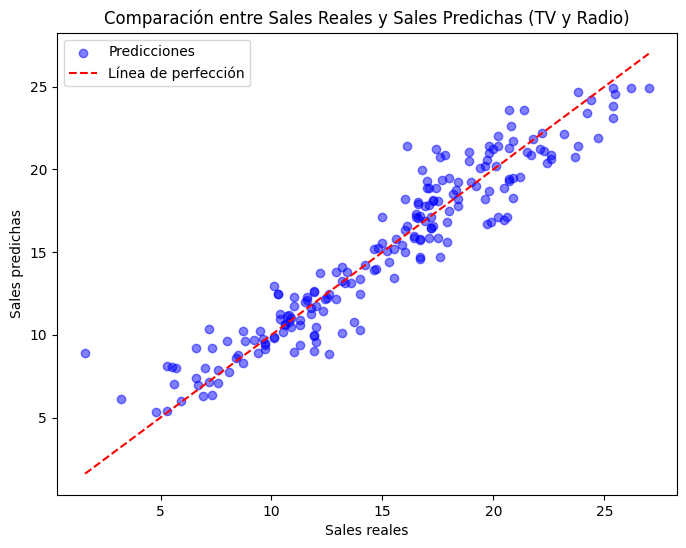

In [17]:
# Visualización de las Predicciones (sin Newspaper)

# 1. Ventas reales contra ventas predichas por el nuevo modelo, con la línea de predicción perfecta.
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred_p6, alpha=0.5, color='blue', label='Predicciones')
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', label='Línea de perfección')
plt.title("Comparación entre Sales Reales y Sales Predichas (TV y Radio)")
plt.xlabel("Sales reales")
plt.ylabel("Sales predichas")
plt.legend()
plt.show()


**Respuesta:**

La gráfica es prácticamente igual a la de la sección 4.6. Los puntos se concentran alrededor de la línea de predicción perfecta, sobre todo en las ventas intermedias (de 8 a 20 aproximadamente), lo que confirma visualmente el R² de 0.9026 de la sección 6.5. Se repiten los mismos errores en los extremos: el modelo sobreestima las ventas bajas (la venta real de 1.6 se predice cerca de 9) y subestima un poco las más altas (ventas reales de 25 a 27 predichas entre 23 y 25). Con esto se ve que eliminar Newspaper no cambió la calidad de las predicciones.

### 6.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels para obtener los valores p.
2. ¿Qué variables tienen p-value menores a 0.05? ¿Cuál es la conclusión sobre esas variables?

In [18]:
# P-values (sin Newspaper)

# 1. Mismo modelo ajustado con statsmodels (OLS); se agrega la constante para incluir el intercepto.
X_p6_const = sm.add_constant(X_p6)
model_sm_p6 = sm.OLS(y, X_p6_const).fit()

# 2. Resumen con coeficientes, errores estándar, estadístico t y P>|t| de cada variable.
print(model_sm_p6.summary())


                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        06:26:39   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

**Respuesta:**

- **Variables con p-value menor a 0.05:** la constante, **TV** y **Radio** tienen P>|t| = **0.000**. Sus estadísticos t son altos (39.726 para TV y 13.522 para Radio) y sus intervalos de confianza al 95 % no incluyen el 0 (TV de 0.052 a 0.057 y Radio de 0.092 a 0.123).
- **Conclusión:** ambas variables tienen un efecto estadísticamente significativo y positivo sobre las ventas, así que todas las variables que quedaron en este modelo son relevantes. Además, frente al resumen del modelo completo de la sección 4.7: el R-squared se mantiene en 0.903, el Adj. R-squared sube de 0.901 a **0.902**, el AIC baja de 774.7 a **772.7** y el BIC de 787.9 a **782.6**. Esto indica que el modelo sin Newspaper explica lo mismo con menos variables.

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

**Respuesta:**

- **¿Cuál de los tres modelos fue el mejor?** El mejor fue el **modelo de la Parte 6 (TV y Radio)**. El modelo de la Parte 5 resultó idéntico al de la Parte 4, porque no se detectó multicolinealidad y no se eliminó ninguna variable. Al comparar la Parte 4 con la Parte 6, ambos tienen prácticamente el mismo ajuste: R² = 0.9026 y RMSE = 1.6450 en los dos casos (MSE de 2.7060 contra 2.7061). Pero el modelo de la Parte 6 lo logra con una variable menos, tiene un Adj. R-squared ligeramente mayor (0.902 contra 0.901), un AIC y un BIC menores (772.7 contra 774.7 y 782.6 contra 787.9), y todas sus variables son significativas (p-value de 0.000 para TV y Radio), mientras que en el modelo completo Newspaper no lo era (p-value de 0.954). Al ser más sencillo y explicar lo mismo, es el modelo preferible.
- **¿Qué atributo tiene más influencia en las ventas?** **TV**. Es la variable con la relación lineal más clara en la sección 2.1, la de mayor correlación con las ventas (0.90 en la sección 2.2) y la de estadístico t más alto en ambos modelos (39.592 en la sección 4.7 y 39.726 en la sección 6.7, contra 12.604 y 13.522 de Radio). Aunque el coeficiente de Radio por unidad invertida es mayor (0.1072 contra 0.0544 de TV en la sección 6.1), la inversión en TV se mueve en un rango mucho más amplio (de 0.7 a 296.4 contra 0 a 49.6 en Radio, según la Parte 1), por lo que es la que explica la mayor parte de las variaciones en las ventas. Radio ocupa el segundo lugar y Newspaper no tiene un efecto significativo.